# No-Rate Analysis by Phase

One bar chart per phase, comparing average no-rate (with 95% CI) across pipeline configurations.
Reference baselines (Top-10 LLMs 0-shot, New Yorker human) included in each chart.

**Note on reference baselines:**
- **Top-10 LLMs (0-shot)**: These are the 10 highest-Elo models from the [EQ-Bench Creative Writing v3](https://eqbench.com/creative_writing.html) leaderboard, writing stories using EQ-Bench's 32 story prompts (different from our 15 story ideas). The no-rate is computed from 100-ending evaluation on those stories.
- **New Yorker (human)**: Professional fiction published in *The New Yorker* (261 stories). These use entirely different story content.
- Because the reference baselines use different story prompts, absolute comparisons should be interpreted cautiously. The references are most useful as **anchors** — showing where vanilla LLM writing and professional human writing fall on the no-rate scale.

In [2]:
import json, os, re
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.facecolor': 'white',
})

BASE = '/project/jevans/maxzhuyt/narrative_project/narrative_ablation/results'
STORIES_DIR = os.path.join(BASE, 'stories')
MIN_WORDS, MAX_WORDS = 500, 5000
LATE_PCT = 80
INFLECTION_SMOOTH_W = 3

# ── Story selection: use ALL valid stories (no cap) ──────────────────────────

def get_valid_story_ids(config_id):
    sdir = os.path.join(STORIES_DIR, config_id)
    if not os.path.isdir(sdir):
        sdir = os.path.join(BASE, 'stories_txt', config_id)
        if not os.path.isdir(sdir):
            return set()
    valid = set()
    for f in os.listdir(sdir):
        if f.endswith('.txt') and not f.startswith('_'):
            wc = len(open(os.path.join(sdir, f)).read().split())
            sid = f.replace('.txt', '')
            if MIN_WORDS <= wc <= MAX_WORDS:
                valid.add(sid)
    return valid

# ── Core metric functions ─────────────────────────────────────────────────────
import glob

def smooth(y, w=INFLECTION_SMOOTH_W):
    y = np.array(y, dtype=float)
    if len(y) < w: return y
    return np.convolve(y, np.ones(w)/w, mode='same')

def story_no_rate_mean(positions):
    nrs = [1 - p['yes_rate'] for p in positions]
    return float(np.mean(nrs)) if nrs else np.nan

def story_no_rate_late(positions):
    pcts = np.array([p['pct'] for p in positions])
    nrs = np.array([1 - p['yes_rate'] for p in positions])
    late = nrs[pcts >= LATE_PCT]
    return float(np.mean(late)) if len(late) > 0 else float(np.mean(nrs[-3:])) if len(nrs) > 0 else np.nan

def story_inflection_rate(positions, max_angle_deg=60):
    pcts = np.array([p['pct'] for p in positions])
    nrs = np.array([1 - p['yes_rate'] for p in positions])
    y = smooth(nrs)
    n = len(y)
    if n < 5: return np.nan
    xn = (pcts - pcts.min()) / (pcts.max() - pcts.min() + 1e-12)
    yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    count = 0
    for i in range(1, n - 1):
        d1 = yn[i] - yn[i-1]
        d2 = yn[i+1] - yn[i]
        if d1 * d2 >= 0: continue
        v1 = np.array([xn[i-1] - xn[i], yn[i-1] - yn[i]])
        v2 = np.array([xn[i+1] - xn[i], yn[i+1] - yn[i]])
        cos_a = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-12)
        angle = np.degrees(np.arccos(np.clip(cos_a, -1, 1)))
        if angle <= max_angle_deg:
            count += 1
    return count / n

def story_post_spike_retention(positions, lookahead=10):
    """Post-spike tension retention: % of peak tension maintained after spikes.
    Higher = tension stays high after peaks (less resolution).
    Lower = tension drops sharply after peaks (more resolution).
    Range: 0-100%."""
    nrs = np.array([1 - p['yes_rate'] for p in positions])
    if len(nrs) < 10: return np.nan
    retentions = []
    for i in range(1, len(nrs) - 1):
        if nrs[i] > nrs[i-1] and nrs[i] > nrs[i+1]:
            future = nrs[i+1:i+1+lookahead]
            if len(future) > 0:
                peak = nrs[i]
                denom = peak if peak > 1e-6 else 1e-6
                retained = np.min(future) / denom * 100.0
                retentions.append(retained)
    return float(np.mean(retentions)) if retentions else np.nan

# ── Load reference baselines (all 4 metrics) ─────────────────────────────────

JUDGE_DIR = '/project/jevans/maxzhuyt/narrative_project/results_endings'
_h_judge = {}
for shard in sorted(glob.glob(os.path.join(JUDGE_DIR, 'ending_judge_sh*.json'))):
    with open(shard) as f:
        _h_judge.update(json.load(f))

nyer_metrics = {'mean_nr': [], 'late_nr': [], 'inflection_60': [], 'post_spike_retention': []}
for _sid, _v in _h_judge.items():
    _g = _v.get('group', '')
    if _g in ('literary', 'nyer_83', 'nyer_expanded'):
        pos = _v['positions']
        if pos:
            nyer_metrics['mean_nr'].append(story_no_rate_mean(pos))
            nyer_metrics['late_nr'].append(story_no_rate_late(pos))
            nyer_metrics['inflection_60'].append(story_inflection_rate(pos, 60))
            nyer_metrics['post_spike_retention'].append(story_post_spike_retention(pos))

for k in nyer_metrics:
    nyer_metrics[k] = np.array([v for v in nyer_metrics[k] if not np.isnan(v)])

CWB_JUDGE = '/project/jevans/maxzhuyt/creative-writing-bench/results/judge/ending_judge.json'
_cwb_judge = {}
if os.path.exists(CWB_JUDGE):
    with open(CWB_JUDGE) as f:
        _cwb_judge = json.load(f)

with open('/project/jevans/maxzhuyt/creative-writing-bench/elo_results.json') as f:
    _elo = json.load(f)

_geom_slugs = set(_v.get('model_slug', '') for _v in _cwb_judge.values())
_slug_elos = {}
for _slug in _geom_slugs:
    for _name in [_slug, _slug.replace('__', '/')]:
        if _name in _elo:
            _slug_elos[_slug] = _elo[_name].get('elo', 0)
            break
_top10_slugs = set(s for s, _ in sorted(_slug_elos.items(), key=lambda x: -x[1])[:10])

llm_metrics = {'mean_nr': [], 'late_nr': [], 'inflection_60': [], 'post_spike_retention': []}
for _sid, _v in _cwb_judge.items():
    if _v.get('model_slug', '') in _top10_slugs:
        pos = _v['positions']
        if pos:
            llm_metrics['mean_nr'].append(story_no_rate_mean(pos))
            llm_metrics['late_nr'].append(story_no_rate_late(pos))
            llm_metrics['inflection_60'].append(story_inflection_rate(pos, 60))
            llm_metrics['post_spike_retention'].append(story_post_spike_retention(pos))

for k in llm_metrics:
    llm_metrics[k] = np.array([v for v in llm_metrics[k] if not np.isnan(v)])

REFS = {}
for metric in ['mean_nr', 'late_nr', 'inflection_60', 'post_spike_retention']:
    REFS[metric] = {
        'llm_mean': np.mean(llm_metrics[metric]) if len(llm_metrics[metric]) > 0 else np.nan,
        'llm_ci': 1.96 * np.std(llm_metrics[metric]) / np.sqrt(len(llm_metrics[metric])) if len(llm_metrics[metric]) > 0 else 0,
        'llm_n': len(llm_metrics[metric]),
        'nyer_mean': np.mean(nyer_metrics[metric]) if len(nyer_metrics[metric]) > 0 else np.nan,
        'nyer_ci': 1.96 * np.std(nyer_metrics[metric]) / np.sqrt(len(nyer_metrics[metric])) if len(nyer_metrics[metric]) > 0 else 0,
        'nyer_n': len(nyer_metrics[metric]),
    }

print(f'Reference baselines (all 4 metrics):')
for metric in ['mean_nr', 'late_nr', 'inflection_60', 'post_spike_retention']:
    r = REFS[metric]
    unit = '%' if 'retention' in metric else ''
    print(f'  {metric:<22s} LLM={r["llm_mean"]:.3f}{unit}±{r["llm_ci"]:.3f} (n={r["llm_n"]})  '
          f'NYer={r["nyer_mean"]:.3f}{unit}±{r["nyer_ci"]:.3f} (n={r["nyer_n"]})')

# ── Helper functions ──────────────────────────────────────────────────────────

def load_judge(config_id):
    path = os.path.join(BASE, 'judge', f'{config_id}_judge.json')
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return None

def get_config_metrics(config_id):
    data = load_judge(config_id)
    if data is None: return None
    valid_ids = get_valid_story_ids(config_id)
    results = {'mean_nr': [], 'late_nr': [], 'inflection_60': [], 'post_spike_retention': []}
    for sid, entry in data.items():
        if valid_ids and sid not in valid_ids: continue
        pos = entry['positions']
        if not pos: continue
        results['mean_nr'].append(story_no_rate_mean(pos))
        results['late_nr'].append(story_no_rate_late(pos))
        results['inflection_60'].append(story_inflection_rate(pos, 60))
        results['post_spike_retention'].append(story_post_spike_retention(pos))
    for k in results:
        results[k] = np.array([v for v in results[k] if not np.isnan(v)])
    return results

# ── Plot function ─────────────────────────────────────────────────────────────

def plot_metric_bars(configs, labels, colors, metric_key, title, ylabel,
                     subtitle=None, ylim=None):
    """Bar chart for any metric with 95% CI + reference baselines."""
    ref = REFS.get(metric_key, {})
    has_refs = not np.isnan(ref.get('llm_mean', np.nan))
    is_pct = 'retention' in metric_key
    
    bar_labels = list(labels)
    bar_colors = list(colors)
    if has_refs:
        bar_labels += ['Top-10 LLMs\n(0-shot)*', 'New Yorker\n(human)*']
        bar_colors += ['#2ca02c', '#984ea3']
    
    means, cis, counts, missing = [], [], [], []
    for i, cfg in enumerate(configs):
        m = get_config_metrics(cfg)
        if m is None or len(m[metric_key]) == 0:
            means.append(0); cis.append(0); counts.append(0); missing.append(i)
            continue
        vals = m[metric_key]
        means.append(np.mean(vals))
        cis.append(1.96 * np.std(vals) / np.sqrt(len(vals)))
        counts.append(len(vals))
    
    if has_refs:
        means.extend([ref['llm_mean'], ref['nyer_mean']])
        cis.extend([ref['llm_ci'], ref['nyer_ci']])
        counts.extend([ref['llm_n'], ref['nyer_n']])
    
    fig, ax = plt.subplots(figsize=(max(10, len(bar_labels) * 1.3 + 1), 6.0))
    x = np.arange(len(means))
    bars = ax.bar(x, means, yerr=cis, capsize=5,
                  color=bar_colors, edgecolor='black', linewidth=0.5, alpha=0.85)
    
    for i in missing:
        bars[i].set_alpha(0.2); bars[i].set_hatch('//')
    
    if has_refs:
        ax.axvline(len(configs) - 0.5, color='gray', linewidth=1, linestyle='--', alpha=0.5)
    
    ax.set_xticks(x)
    ax.set_xticklabels(bar_labels, rotation=20, ha='right')
    ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(ylim)
    
    if subtitle:
        ax.set_title(f'{title}\n', fontsize=13, fontweight='bold', pad=12)
        fig.text(0.5, 0.94, subtitle, ha='center', va='top', fontsize=9, color='#555', style='italic')
    else:
        ax.set_title(title, fontsize=13, fontweight='bold')
    
    fmt = '{:.1f}%' if is_pct else '{:.3f}'
    for i, (bar, m, ci, n) in enumerate(zip(bars, means, cis, counts)):
        if i in missing or np.isnan(m): continue
        label_text = f'{fmt.format(m)}\n(n={n})'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + ci + 0.005,
                label_text, ha='center', va='bottom', fontsize=8, fontweight='bold')
    
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(rect=[0, 0.02, 1, 0.93])
    plt.show()

# Verify counts
for cfg in sorted(d.replace('_judge.json','') for d in os.listdir(os.path.join(BASE, 'judge')) if d.endswith('_judge.json')):
    valid = get_valid_story_ids(cfg)
    data = load_judge(cfg)
    judged = len(data) if data else 0
    print(f'  {cfg}: {len(valid)} valid, {judged} judged')

print('\nSetup complete. 4 metrics: mean_nr, late_nr, inflection_60, post_spike_retention')

Reference baselines (all 4 metrics):
  mean_nr                LLM=0.630±0.020 (n=320)  NYer=0.765±0.018 (n=261)
  late_nr                LLM=0.215±0.019 (n=320)  NYer=0.607±0.027 (n=261)
  inflection_60          LLM=0.106±0.008 (n=319)  NYer=0.200±0.011 (n=261)
  post_spike_retention   LLM=23.309%±1.655 (n=318)  NYer=51.713%±2.196 (n=261)
  cwb_narrative_sonnet46: 96 valid, 96 judged
  cwb_vanilla_sonnet46: 95 valid, 95 judged
  full_fulltext: 44 valid, 44 judged
  full_title: 45 valid, 45 judged
  fulltext_beats10: 45 valid, 15 judged
  fulltext_beats3: 45 valid, 15 judged
  fulltext_beats5: 45 valid, 15 judged
  idea_bare: 16 valid, 16 judged
  idea_full: 113 valid, 17 judged
  idea_instruction_vanilla: 15 valid, 15 judged
  idea_no_priming: 114 valid, 18 judged
  idea_no_taxonomy_bugged: 15 valid, 15 judged
  idea_no_tropes: 112 valid, 16 judged
  idea_tax_only: 109 valid, 18 judged
  idea_tropes_only: 18 valid, 18 judged
  idea_vanilla: 15 valid, 16 judged
  instruction_vanilla: 44

## Phase 1 — Structural Pipeline Ablations

**Controlled for:** Fixed 15 story ideas, Opus 4.6, fulltext/title warmup style = c1_specific

15 story ideas × 3 iterations = 45 stories per config.
Tests: vanilla vs warmup modes (title/fulltext/none) vs beat count (full/3).

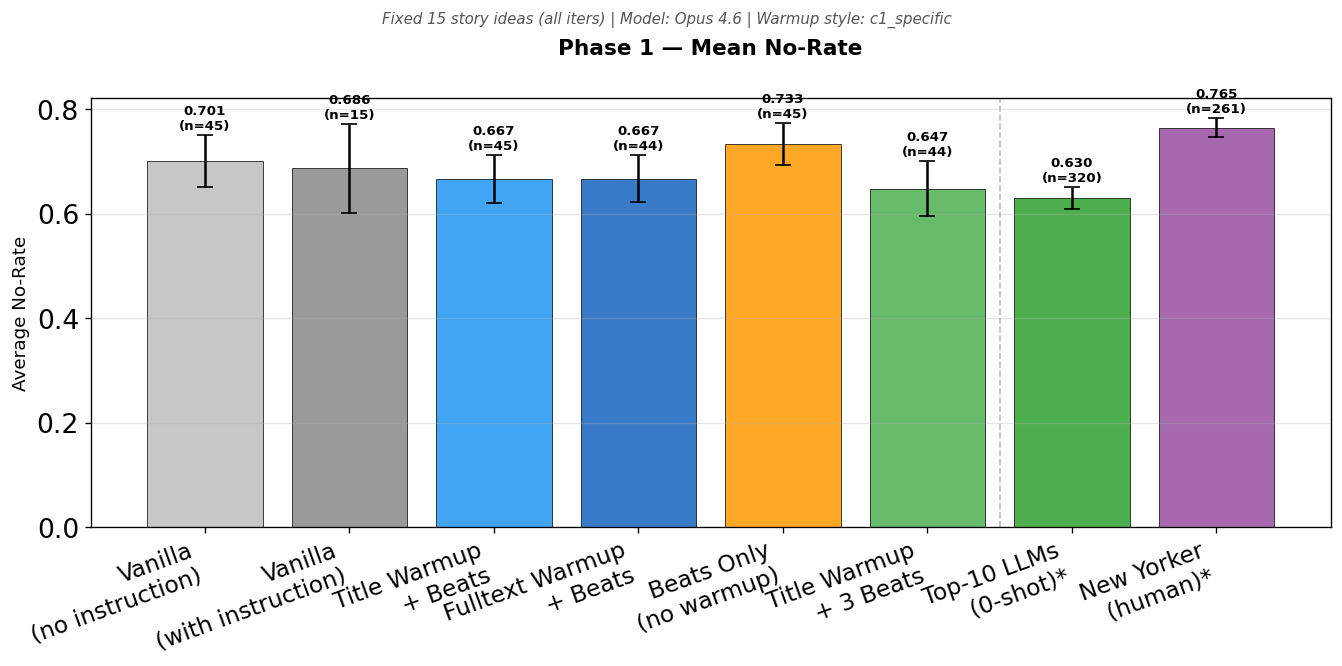

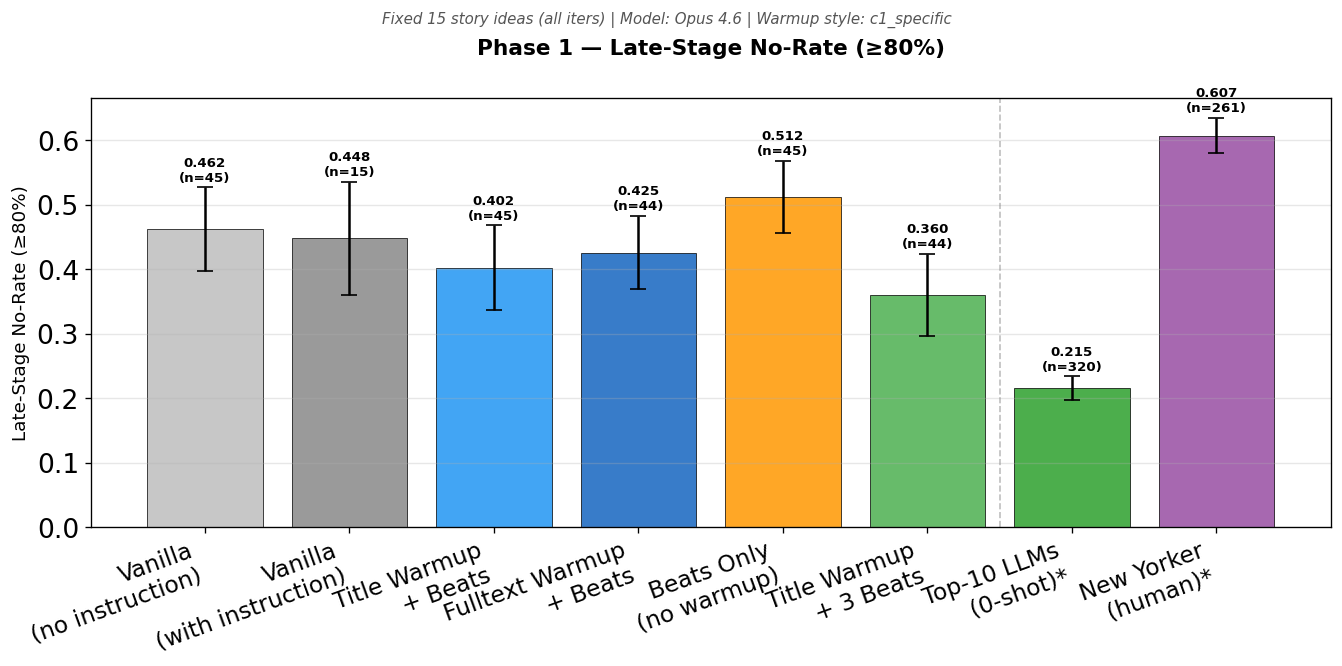

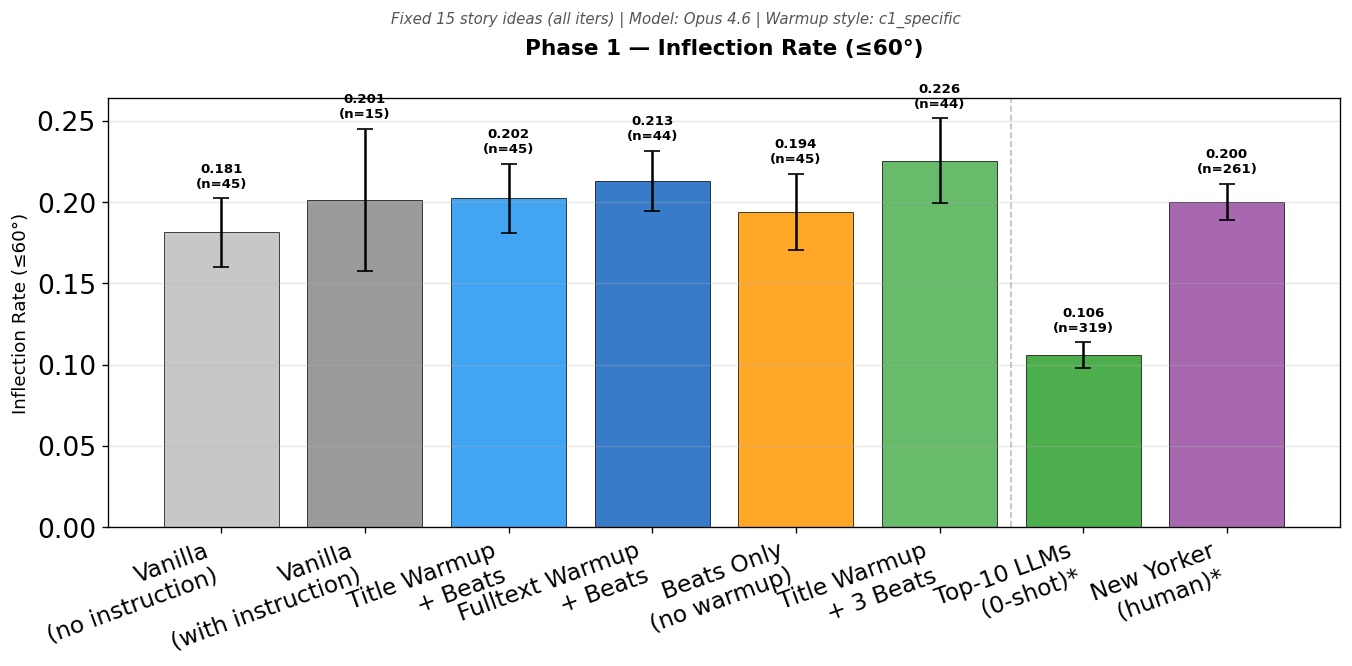

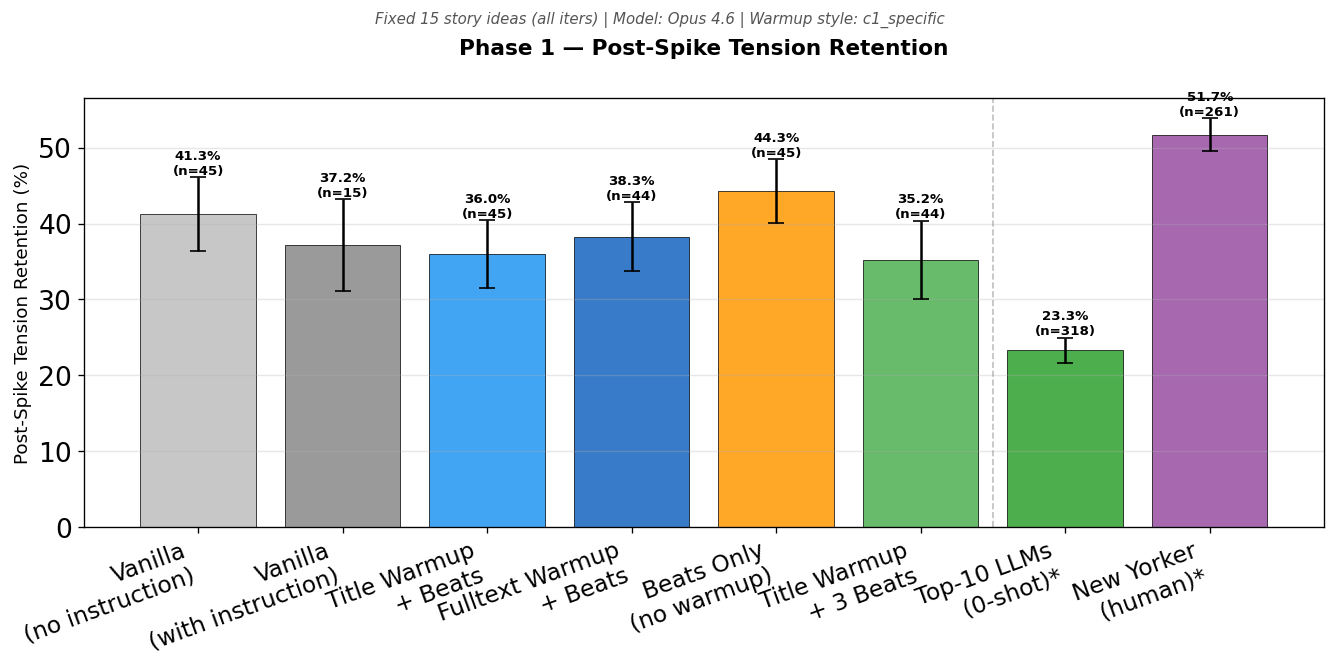

In [3]:
PH1_CONFIGS = ['vanilla', 'instruction_vanilla', 'full_title', 'full_fulltext', 'no_warmup', 'short_beats']
PH1_LABELS = [
    'Vanilla\n(no instruction)',
    'Vanilla\n(with instruction)',
    'Title Warmup\n+ Beats',
    'Fulltext Warmup\n+ Beats',
    'Beats Only\n(no warmup)',
    'Title Warmup\n+ 3 Beats',
]
PH1_COLORS = ['#BDBDBD', '#888888', '#2196F3', '#1565C0', '#FF9800', '#4CAF50']
PH1_SUB = 'Fixed 15 story ideas (all iters) | Model: Opus 4.6 | Warmup style: c1_specific'

for metric, ylabel, title_suffix in [
    ('mean_nr', 'Average No-Rate', 'Mean No-Rate'),
    ('late_nr', f'Late-Stage No-Rate (≥{LATE_PCT}%)', f'Late-Stage No-Rate (≥{LATE_PCT}%)'),
    ('inflection_60', 'Inflection Rate (≤60°)', 'Inflection Rate (≤60°)'),
    ('post_spike_retention', 'Post-Spike Tension Retention (%)', 'Post-Spike Tension Retention'),
]:
    plot_metric_bars(
        PH1_CONFIGS, PH1_LABELS, PH1_COLORS, metric,
        f'Phase 1 — {title_suffix}', ylabel, subtitle=PH1_SUB,
    )

Stories with beat sheets: 223
Beat sheet word count: mean=2270, median=2340, range=578-2852


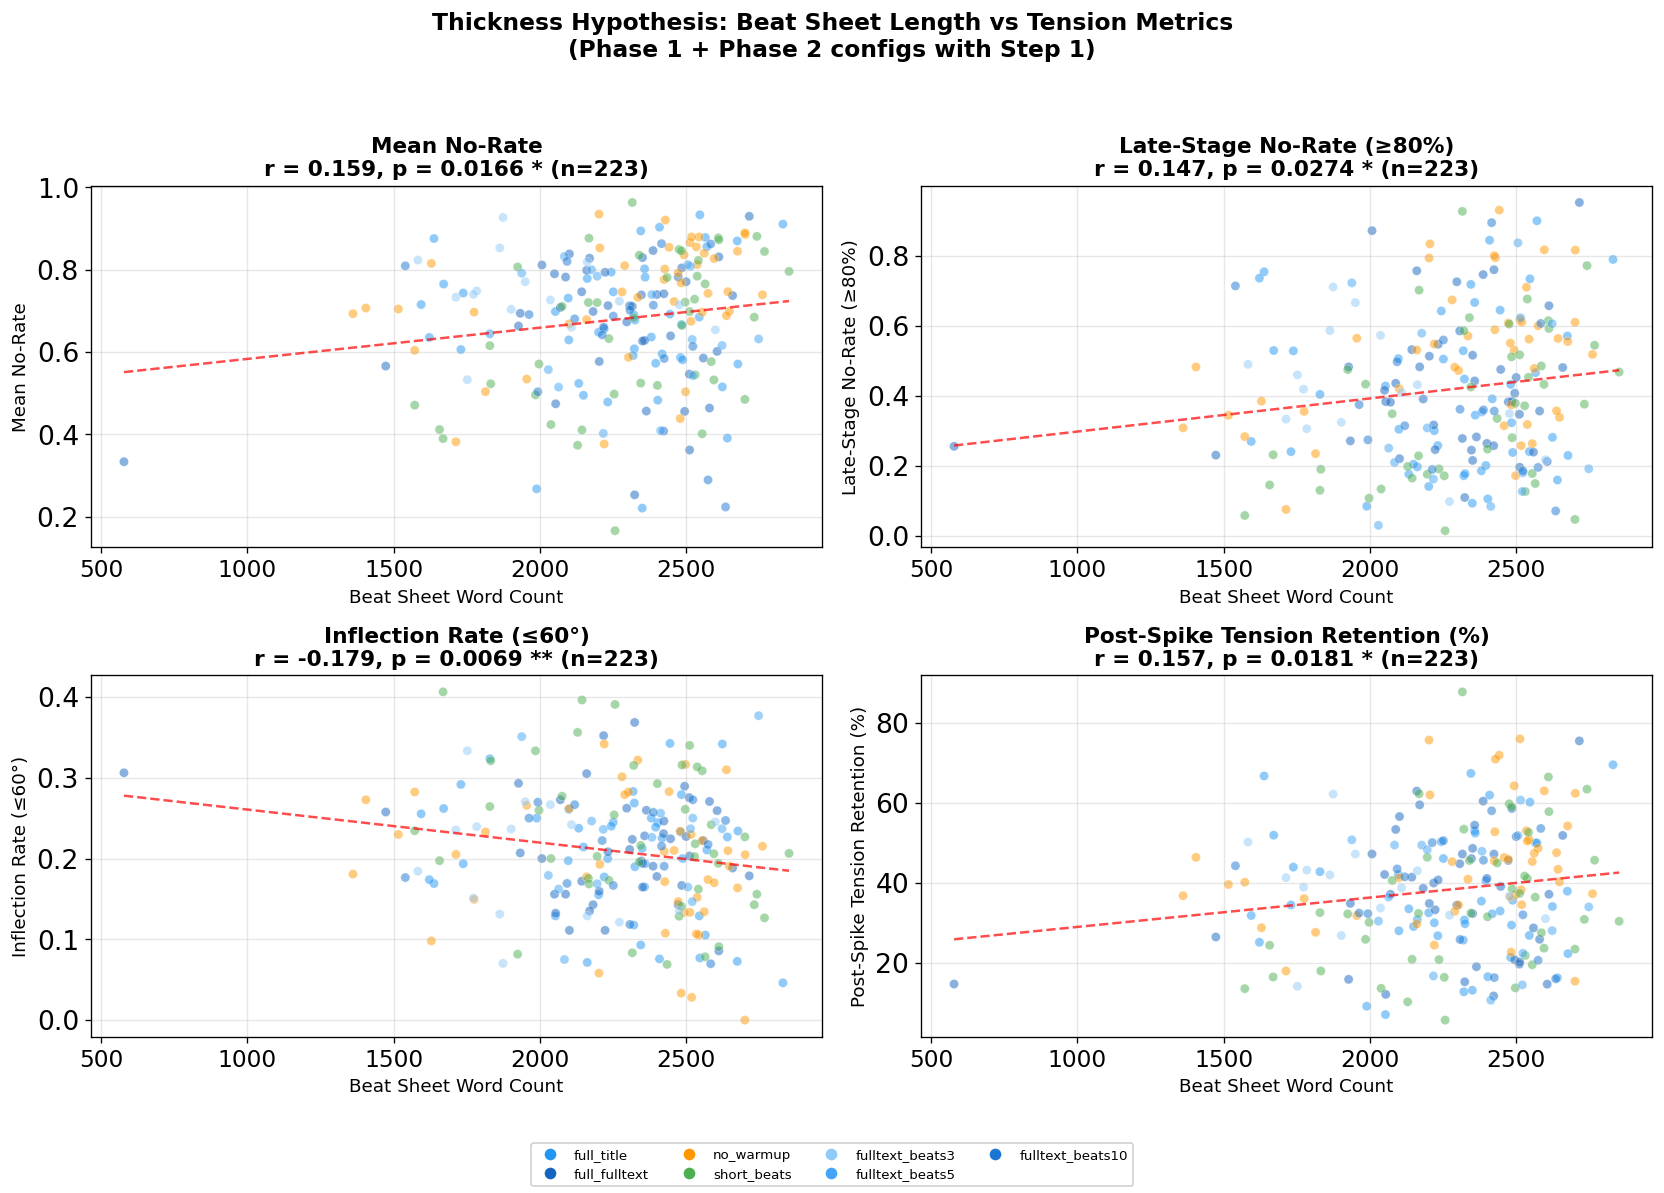


Metric                                     r          p     n   Sig Interpretation
--------------------------------------------------------------------------------
  Mean No-Rate                         0.159     0.0166   223     * positive
  Late-Stage No-Rate (≥80%)            0.147     0.0274   223     * positive
  Inflection Rate (≤60°)              -0.179     0.0069   223    ** negative
  Post-Spike Tension Retention (%)     0.157     0.0181   223     * positive


In [4]:
# ── Thickness Hypothesis: beat sheet word count vs metrics (Phase 1 + 2) ──────
# For p-value: use t-statistic from r, df = n-2
import math

def pearson_p(r, n):
    """Two-tailed p-value for Pearson r with n observations."""
    if n <= 2 or abs(r) >= 1.0:
        return 0.0 if abs(r) >= 1.0 else 1.0
    t = r * math.sqrt((n - 2) / (1 - r**2))
    # Approximate p from t using normal for large n, exact for small
    # Use incomplete beta function approximation
    df = n - 2
    x = df / (df + t**2)
    # Regularized incomplete beta via continued fraction (good enough for our needs)
    # For simplicity, use the scipy-free approximation: p ≈ 2 * (1 - Φ(|t|)) for df > 30
    if df > 30:
        from math import erf
        p = 2 * (1 - 0.5 * (1 + erf(abs(t) / math.sqrt(2))))
    else:
        # For small df, use a simple numerical integration
        # t-distribution CDF via approximation
        a = df / 2.0
        p = 1.0  # fallback
        try:
            # Use the regularized incomplete beta function
            # I_x(a,b) where x = df/(df+t^2), a=df/2, b=1/2
            # Simple series expansion
            x = df / (df + t**2)
            # For the beta CDF, use a rough approximation
            z = abs(t) * (1 - 1/(4*df)) / math.sqrt(1 + t**2/(2*df))
            from math import erf
            p = 2 * (1 - 0.5 * (1 + erf(z / math.sqrt(2))))
        except:
            p = 1.0
    return max(p, 1e-10)

BEAT_CONFIGS = ['full_title', 'full_fulltext', 'no_warmup', 'short_beats',
                'fulltext_beats3', 'fulltext_beats5', 'fulltext_beats10']

beat_wcs = []
beat_metrics = []

for cfg in BEAT_CONFIGS:
    data = load_judge(cfg)
    if data is None: continue
    valid_ids = get_valid_story_ids(cfg)
    
    stories_dir = os.path.join(STORIES_DIR, cfg)
    if not os.path.isdir(stories_dir):
        continue
    
    for f in os.listdir(stories_dir):
        if not f.endswith('_meta.json') or f.startswith('_'):
            continue
        sid = f.replace('_meta.json', '')
        if valid_ids and sid not in valid_ids:
            continue
        if sid not in data:
            continue
        
        meta = json.load(open(os.path.join(stories_dir, f)))
        beats = meta.get('narrative_beats', '')
        if not beats:
            continue
        
        beat_wc = len(beats.split())
        pos = data[sid]['positions']
        if not pos:
            continue
        
        mnr = story_no_rate_mean(pos)
        lnr = story_no_rate_late(pos)
        ir = story_inflection_rate(pos, 60)
        ps = story_post_spike_retention(pos)
        
        beat_wcs.append(beat_wc)
        beat_metrics.append({'mean_nr': mnr, 'late_nr': lnr, 'inflection_60': ir, 'post_spike_retention': ps,
                            'config': cfg, 'sid': sid})

beat_wcs = np.array(beat_wcs)
if len(beat_wcs) > 0:
    print(f"Stories with beat sheets: {len(beat_wcs)}")
    print(f"Beat sheet word count: mean={beat_wcs.mean():.0f}, median={np.median(beat_wcs):.0f}, "
          f"range={beat_wcs.min()}-{beat_wcs.max()}")

    # Correlations
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    metric_names = [
        ('mean_nr', 'Mean No-Rate'),
        ('late_nr', f'Late-Stage No-Rate (≥{LATE_PCT}%)'),
        ('inflection_60', 'Inflection Rate (≤60°)'),
        ('post_spike_retention', 'Post-Spike Tension Retention (%)'),
    ]

    cfg_colors_map = {
        'full_title': '#2196F3', 'full_fulltext': '#1565C0', 'no_warmup': '#FF9800',
        'short_beats': '#4CAF50', 'fulltext_beats3': '#90CAF9',
        'fulltext_beats5': '#42A5F5', 'fulltext_beats10': '#1976D2',
    }

    for ax, (key, label) in zip(axes.flat, metric_names):
        y_vals = np.array([m[key] for m in beat_metrics])
        mask = ~np.isnan(y_vals)
        x_clean = beat_wcs[mask]
        y_clean = y_vals[mask]
        
        if len(x_clean) < 5:
            ax.text(0.5, 0.5, 'Insufficient data', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(label)
            continue
        
        r = np.corrcoef(x_clean, y_clean)[0, 1]
        p = pearson_p(r, len(x_clean))
        
        colors_scatter = [cfg_colors_map.get(m['config'], '#888') for m, v in zip(beat_metrics, mask) if v]
        ax.scatter(x_clean, y_clean, c=colors_scatter, alpha=0.5, s=30, edgecolors='white', linewidth=0.3)
        
        z = np.polyfit(x_clean, y_clean, 1)
        poly = np.poly1d(z)
        x_range = np.linspace(x_clean.min(), x_clean.max(), 100)
        ax.plot(x_range, poly(x_range), 'r--', lw=1.5, alpha=0.7)
        
        ax.set_xlabel('Beat Sheet Word Count')
        ax.set_ylabel(label)
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        ax.set_title(f'{label}\nr = {r:.3f}, p = {p:.4f} {sig} (n={len(x_clean)})', fontweight='bold')
        ax.grid(alpha=0.3)

    # Legend for configs
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c, label=cfg, markersize=8)
                       for cfg, c in cfg_colors_map.items()]
    fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=8, framealpha=0.9)

    plt.suptitle('Thickness Hypothesis: Beat Sheet Length vs Tension Metrics\n(Phase 1 + Phase 2 configs with Step 1)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0.06, 1, 0.95])
    plt.show()

    # Summary table
    print(f"\n{'Metric':<35s} {'r':>8} {'p':>10} {'n':>5} {'Sig':>5} {'Interpretation'}")
    print("-" * 80)
    for key, label in metric_names:
        y_vals = np.array([m[key] for m in beat_metrics])
        mask = ~np.isnan(y_vals)
        if mask.sum() < 5:
            print(f"  {label:<33s} {'—':>8} {'—':>10} {'—':>5}")
            continue
        r = np.corrcoef(beat_wcs[mask], y_vals[mask])[0, 1]
        p = pearson_p(r, mask.sum())
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        interp = "positive" if r > 0.1 else "negative" if r < -0.1 else "negligible"
        print(f"  {label:<33s} {r:>8.3f} {p:>10.4f} {mask.sum():>5} {sig:>5} {interp}")
else:
    print("No stories with beat sheets found yet (jobs may still be running).")

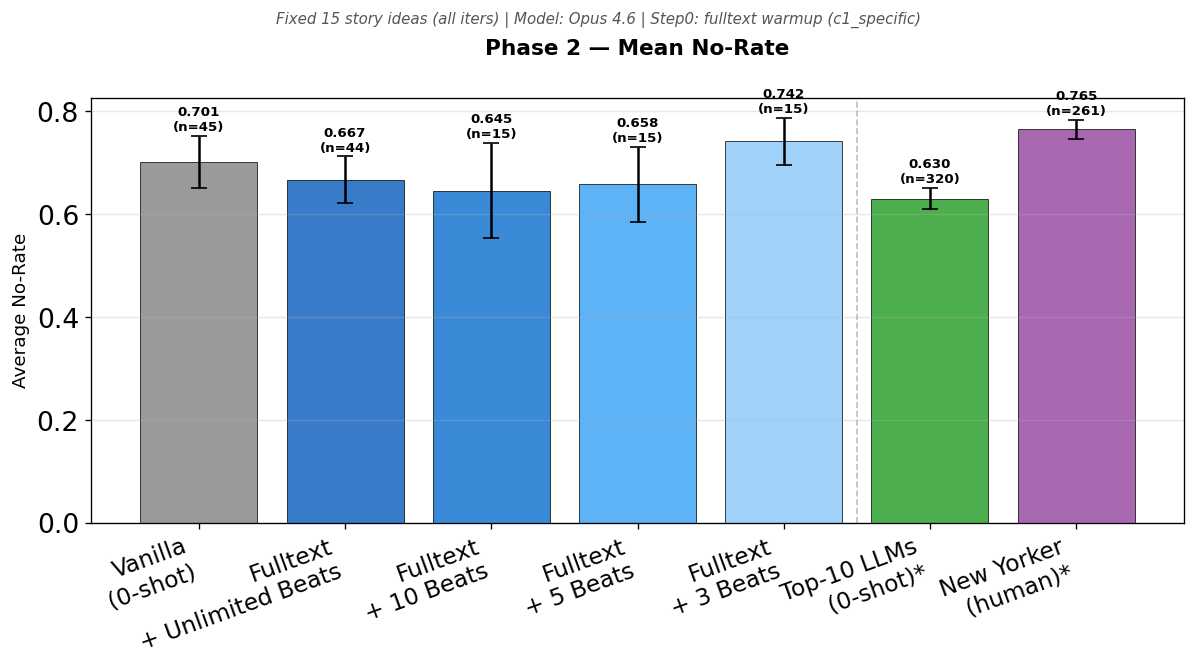

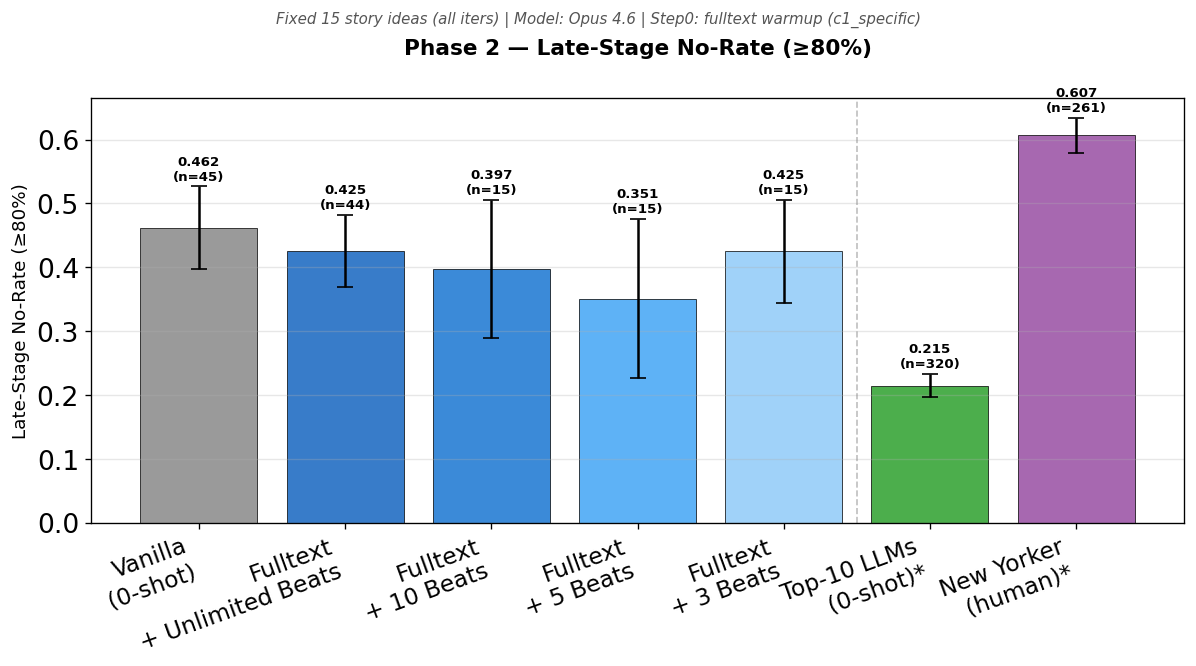

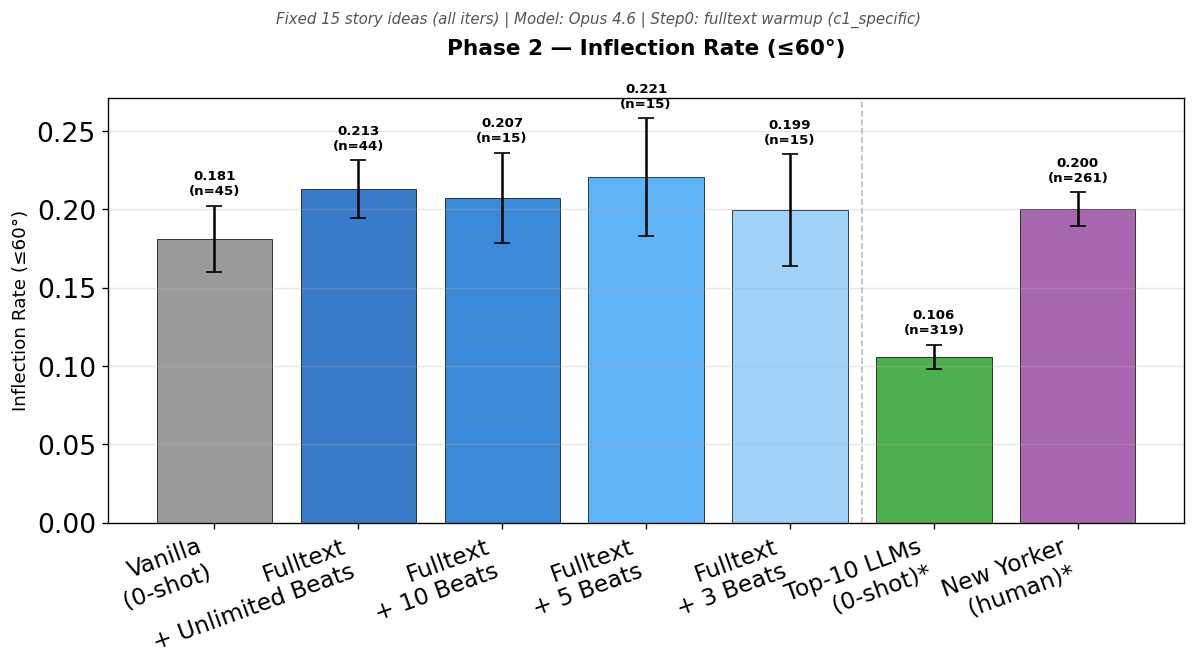

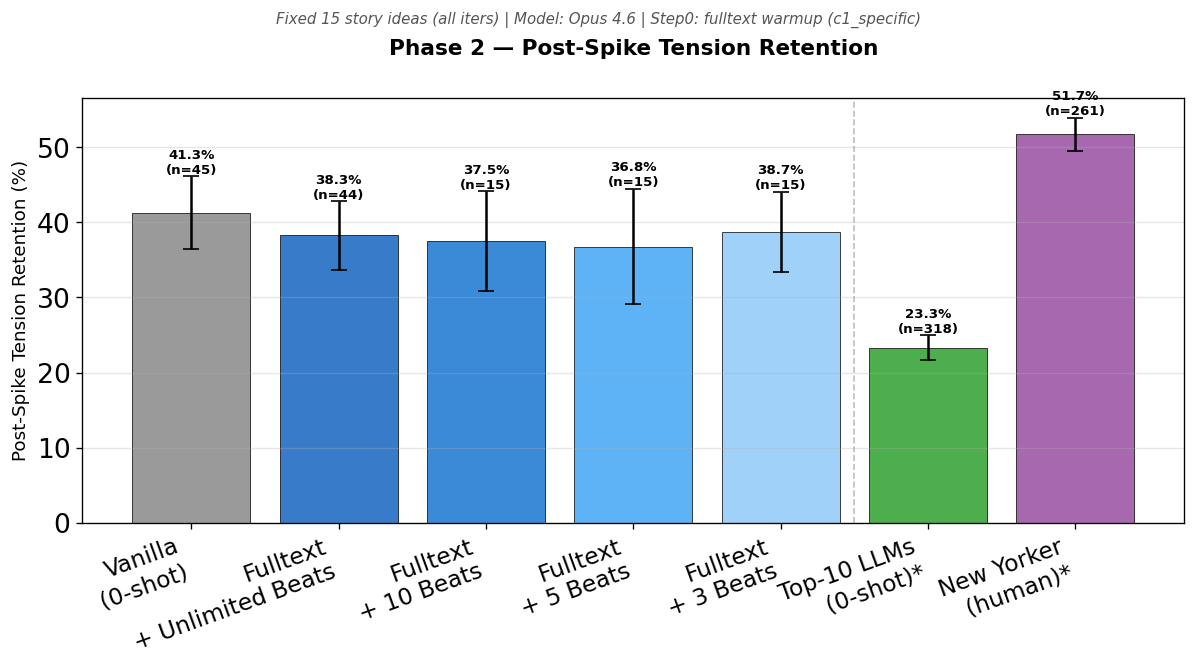

In [5]:
PH2_CONFIGS = ['vanilla', 'full_fulltext', 'fulltext_beats10', 'fulltext_beats5', 'fulltext_beats3']
PH2_LABELS = [
    'Vanilla\n(0-shot)',
    'Fulltext\n+ Unlimited Beats',
    'Fulltext\n+ 10 Beats',
    'Fulltext\n+ 5 Beats',
    'Fulltext\n+ 3 Beats',
]
PH2_COLORS = ['#888888', '#1565C0', '#1976D2', '#42A5F5', '#90CAF9']
PH2_SUB = 'Fixed 15 story ideas (all iters) | Model: Opus 4.6 | Step0: fulltext warmup (c1_specific)'

for metric, ylabel, title_suffix in [
    ('mean_nr', 'Average No-Rate', 'Mean No-Rate'),
    ('late_nr', f'Late-Stage No-Rate (≥{LATE_PCT}%)', f'Late-Stage No-Rate (≥{LATE_PCT}%)'),
    ('inflection_60', 'Inflection Rate (≤60°)', 'Inflection Rate (≤60°)'),
    ('post_spike_retention', 'Post-Spike Tension Retention (%)', 'Post-Spike Tension Retention'),
]:
    plot_metric_bars(
        PH2_CONFIGS, PH2_LABELS, PH2_COLORS, metric,
        f'Phase 2 — {title_suffix}', ylabel, subtitle=PH2_SUB,
    )

## Phase 2 — Beat Count Sweep

**Controlled for:** Fixed 15 story ideas, Opus 4.6, step0 = fulltext warmup (c1_specific)

15 story ideas × 1 iteration = 15 stories per config.
Step0 = fulltext held constant. Varies: --step1-max-beats (unlimited, 10, 5, 3).
Includes vanilla baseline for reference.

## Phase 1+2 — Effect of Step 0 (Warmup) and Step 1 (Beats)

Instead of comparing individual configs, we group by **whether they have Step 0** (warmup from reference story) and **whether they have Step 1** (beat sheet / to-do list). All Phase 1+2 configs use the same 15 fixed story ideas, so differences reflect pipeline structure, not idea quality.

| Group | Configs | Description |
|---|---|---|
| No pipeline | vanilla, instruction_vanilla | Raw idea → story |
| Step 1 only | no_warmup | Beats from scratch (no reference) |
| Step 0 + Step 1 | full_title, full_fulltext, short_beats, fulltext_beats3/5/10 | Warmup → beats → story |

In [6]:
# ── Effect of Step 0 and Step 1 on all metrics ──────────────────────────────

# Define groups
GROUPS = {
    'No pipeline (vanilla)':     ['vanilla', 'instruction_vanilla'],
    'Step 1 only (no warmup)':   ['no_warmup'],
    'Step 0 (title) + Step 1':   ['short_beats', 'full_title'],
    'Step 0 (fulltext) + Step 1': ['full_fulltext', 'fulltext_beats3', 'fulltext_beats5', 'fulltext_beats10'],
}

METRIC_LABELS = [
    ('mean_nr', 'Mean NR'),
    ('late_nr', f'Late NR (≥{LATE_PCT}%)'),
    ('inflection_60', 'Inflection (≤60°)'),
    ('post_spike_retention', 'Retention (%)'),
]

# Collect per-group metrics
group_data = {}
for gname, cfgs in GROUPS.items():
    all_vals = {k: [] for k, _ in METRIC_LABELS}
    n_stories = 0
    for cfg in cfgs:
        m = get_config_metrics(cfg)
        if m is None: continue
        for k, _ in METRIC_LABELS:
            all_vals[k].extend(m[k].tolist())
        n_stories += len(m['mean_nr'])
    group_data[gname] = {'n': n_stories}
    for k, _ in METRIC_LABELS:
        v = np.array(all_vals[k])
        v = v[~np.isnan(v)]
        group_data[gname][k] = (np.mean(v), 1.96*np.std(v)/np.sqrt(len(v))) if len(v) > 0 else (np.nan, 0)

# Table 1: Effect of Step 1 (beats vs no beats)
print('=' * 95)
print('TABLE 1: Effect of Step 1 (having a to-do list vs not)')
print('=' * 95)
print(f"{'Group':<35s} {'n':>4}", end='')
for _, label in METRIC_LABELS:
    print(f'  {label:>14s}', end='')
print()
print('-' * 95)

no_step1 = ['vanilla', 'instruction_vanilla']
has_step1 = ['short_beats', 'full_title', 'full_fulltext', 'no_warmup',
             'fulltext_beats3', 'fulltext_beats5', 'fulltext_beats10']

for label, cfgs in [('WITHOUT Step 1 (no beats)', no_step1), ('WITH Step 1 (beats)', has_step1)]:
    all_vals = {k: [] for k, _ in METRIC_LABELS}
    n = 0
    for cfg in cfgs:
        m = get_config_metrics(cfg)
        if m is None: continue
        for k, _ in METRIC_LABELS:
            all_vals[k].extend(m[k].tolist())
        n += len(m['mean_nr'])
    print(f'{label:<35s} {n:>4}', end='')
    for k, _ in METRIC_LABELS:
        v = np.array([x for x in all_vals[k] if not np.isnan(x)])
        if len(v) > 0:
            ci = 1.96*np.std(v)/np.sqrt(len(v))
            unit = '%' if 'retention' in k.lower() or 'Retention' in k else ''
            print(f'  {np.mean(v):>8.3f}{unit}±{ci:.3f}', end='')
        else:
            print(f'  {"—":>14s}', end='')
    print()

# Compute deltas
print(f"{'  DELTA (with - without)':<35s} {'':>4}", end='')
for k, _ in METRIC_LABELS:
    v_no = [x for cfg in no_step1 for x in (get_config_metrics(cfg) or {}).get(k, []) if not np.isnan(x)]
    v_yes = [x for cfg in has_step1 for x in (get_config_metrics(cfg) or {}).get(k, []) if not np.isnan(x)]
    if v_no and v_yes:
        delta = np.mean(v_yes) - np.mean(v_no)
        print(f'  {delta:>+13.3f}', end='')
    else:
        print(f'  {"—":>14s}', end='')
print()

# Table 2: Effect of Step 0 (warmup type, among configs WITH step 1)
print(f'\n{"="*95}')
print('TABLE 2: Effect of Step 0 (warmup type, among configs WITH Step 1)')
print('=' * 95)
print(f"{'Warmup type':<35s} {'n':>4}", end='')
for _, label in METRIC_LABELS:
    print(f'  {label:>14s}', end='')
print()
print('-' * 95)

warmup_groups = [
    ('No warmup (beats from scratch)', ['no_warmup']),
    ('Title warmup', ['short_beats', 'full_title']),
    ('Fulltext warmup', ['full_fulltext', 'fulltext_beats3', 'fulltext_beats5', 'fulltext_beats10']),
]

for label, cfgs in warmup_groups:
    all_vals = {k: [] for k, _ in METRIC_LABELS}
    n = 0
    for cfg in cfgs:
        m = get_config_metrics(cfg)
        if m is None: continue
        for k, _ in METRIC_LABELS:
            all_vals[k].extend(m[k].tolist())
        n += len(m['mean_nr'])
    print(f'{label:<35s} {n:>4}', end='')
    for k, _ in METRIC_LABELS:
        v = np.array([x for x in all_vals[k] if not np.isnan(x)])
        if len(v) > 0:
            ci = 1.96*np.std(v)/np.sqrt(len(v))
            unit = '%' if 'retention' in k.lower() else ''
            print(f'  {np.mean(v):>8.3f}{unit}±{ci:.3f}', end='')
        else:
            print(f'  {"—":>14s}', end='')
    print()

# Table 3: Per-config detail (all Phase 1+2)
print(f'\n{"="*95}')
print('TABLE 3: All Phase 1+2 configs (detail)')
print('=' * 95)
print(f"{'Config':<28s} {'Step0':<10s} {'Step1':<10s} {'n':>4}", end='')
for _, label in METRIC_LABELS:
    print(f'  {label:>12s}', end='')
print()
print('-' * 95)

config_meta = {
    'vanilla':          ('—', '—'),
    'instruction_vanilla': ('—', '—'),
    'no_warmup':        ('—', 'full'),
    'short_beats':      ('title', '3 beats'),
    'full_title':       ('title', 'full'),
    'full_fulltext':    ('fulltext', 'full'),
    'fulltext_beats3':  ('fulltext', '3 beats'),
    'fulltext_beats5':  ('fulltext', '5 beats'),
    'fulltext_beats10': ('fulltext', '10 beats'),
}

for cfg in ['vanilla', 'instruction_vanilla', 'no_warmup', 'short_beats', 'full_title',
            'full_fulltext', 'fulltext_beats3', 'fulltext_beats5', 'fulltext_beats10']:
    m = get_config_metrics(cfg)
    s0, s1 = config_meta[cfg]
    if m is None:
        print(f'{cfg:<28s} {s0:<10s} {s1:<10s}  — no data')
        continue
    n = len(m['mean_nr'])
    print(f'{cfg:<28s} {s0:<10s} {s1:<10s} {n:>4}', end='')
    for k, _ in METRIC_LABELS:
        v = m[k]
        v = v[~np.isnan(v)]
        if len(v) > 0:
            ci = 1.96*np.std(v)/np.sqrt(len(v))
            print(f'  {np.mean(v):>7.3f}±{ci:.3f}', end='')
        else:
            print(f'  {"—":>12s}', end='')
    print()

TABLE 1: Effect of Step 1 (having a to-do list vs not)
Group                                  n         Mean NR  Late NR (≥80%)  Inflection (≤60°)   Retention (%)
-----------------------------------------------------------------------------------------------
WITHOUT Step 1 (no beats)             60     0.697±0.043     0.458±0.054     0.186±0.019    40.244%±3.970
WITH Step 1 (beats)                  223     0.679±0.021     0.418±0.028     0.209±0.010    38.306%±2.035
  DELTA (with - without)                         -0.018         -0.040         +0.022         -1.937

TABLE 2: Effect of Step 0 (warmup type, among configs WITH Step 1)
Warmup type                            n         Mean NR  Late NR (≥80%)  Inflection (≤60°)   Retention (%)
-----------------------------------------------------------------------------------------------
No warmup (beats from scratch)        45     0.733±0.040     0.512±0.056     0.194±0.024    44.293%±4.177
Title warmup                          89     0.657

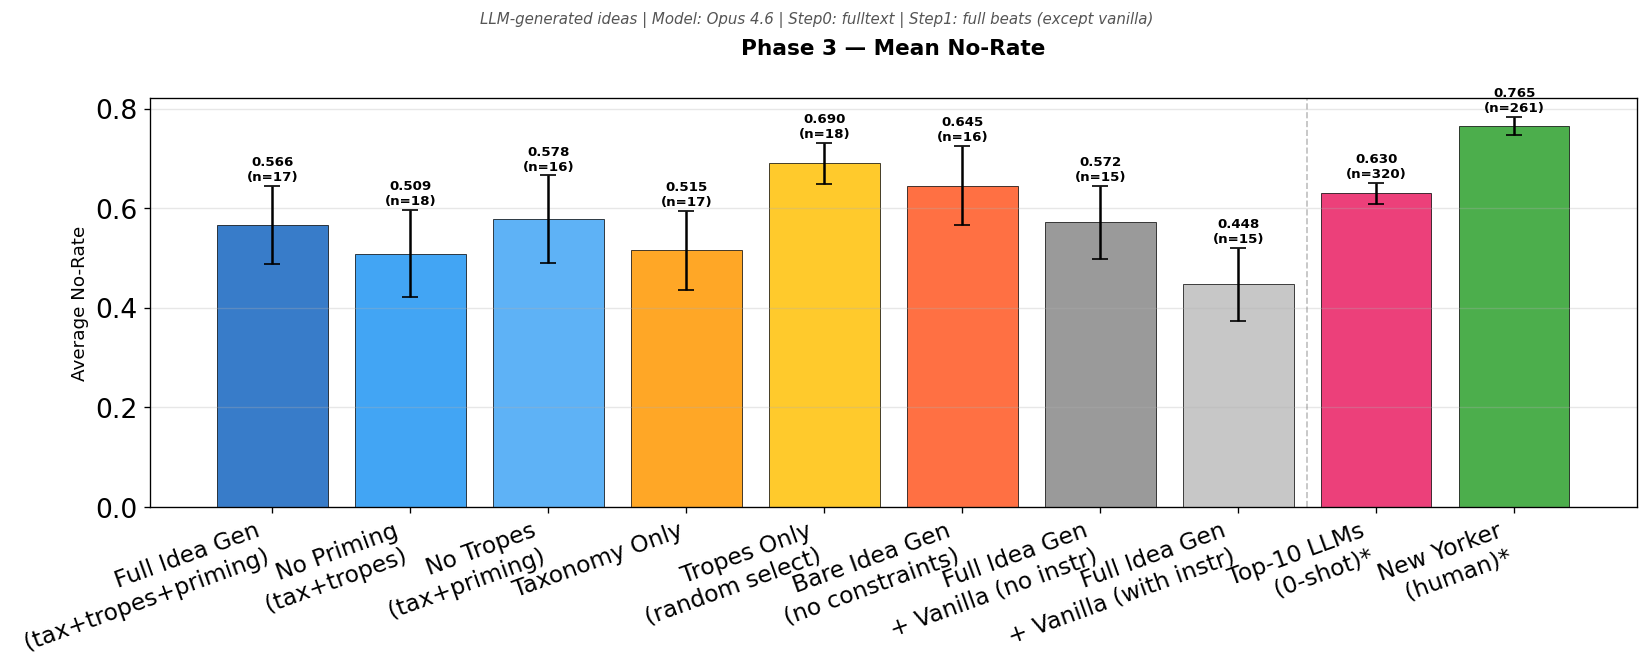

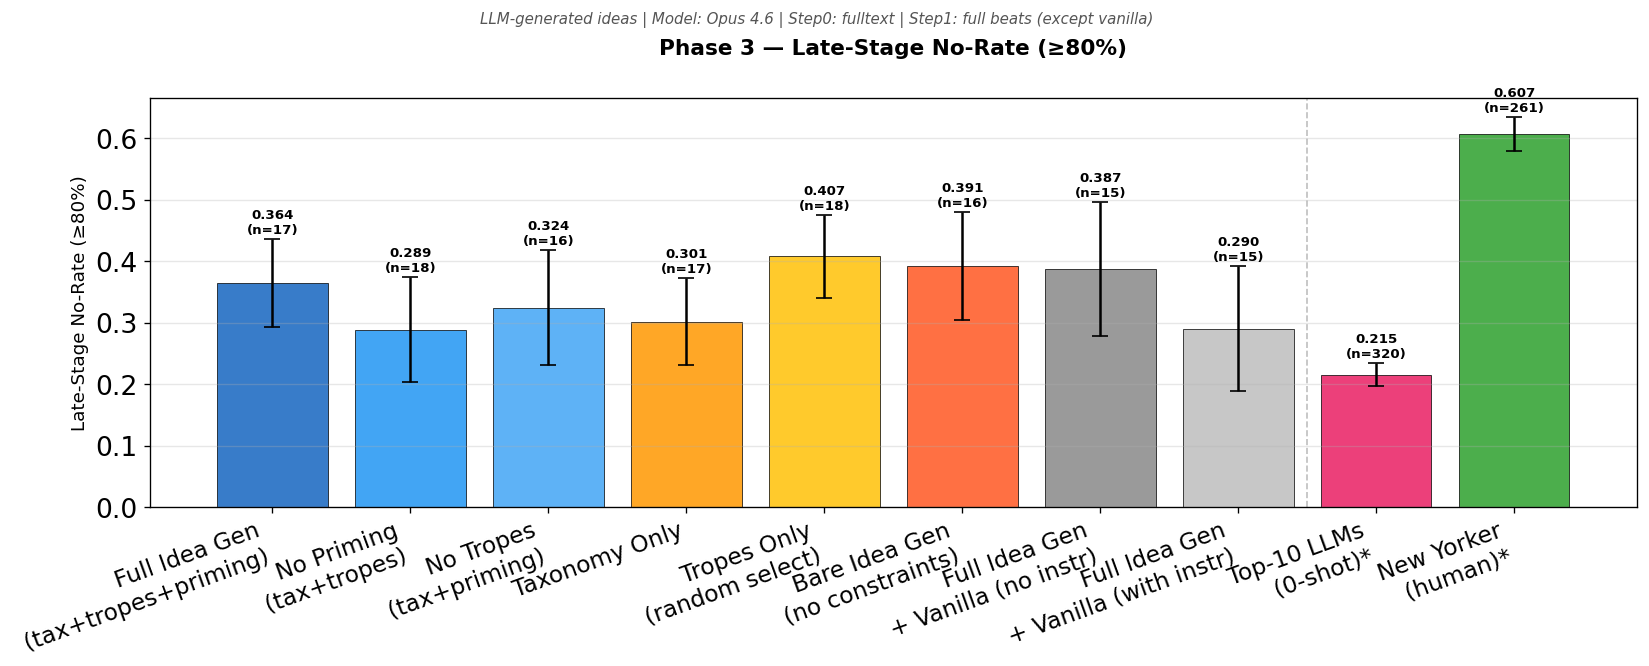

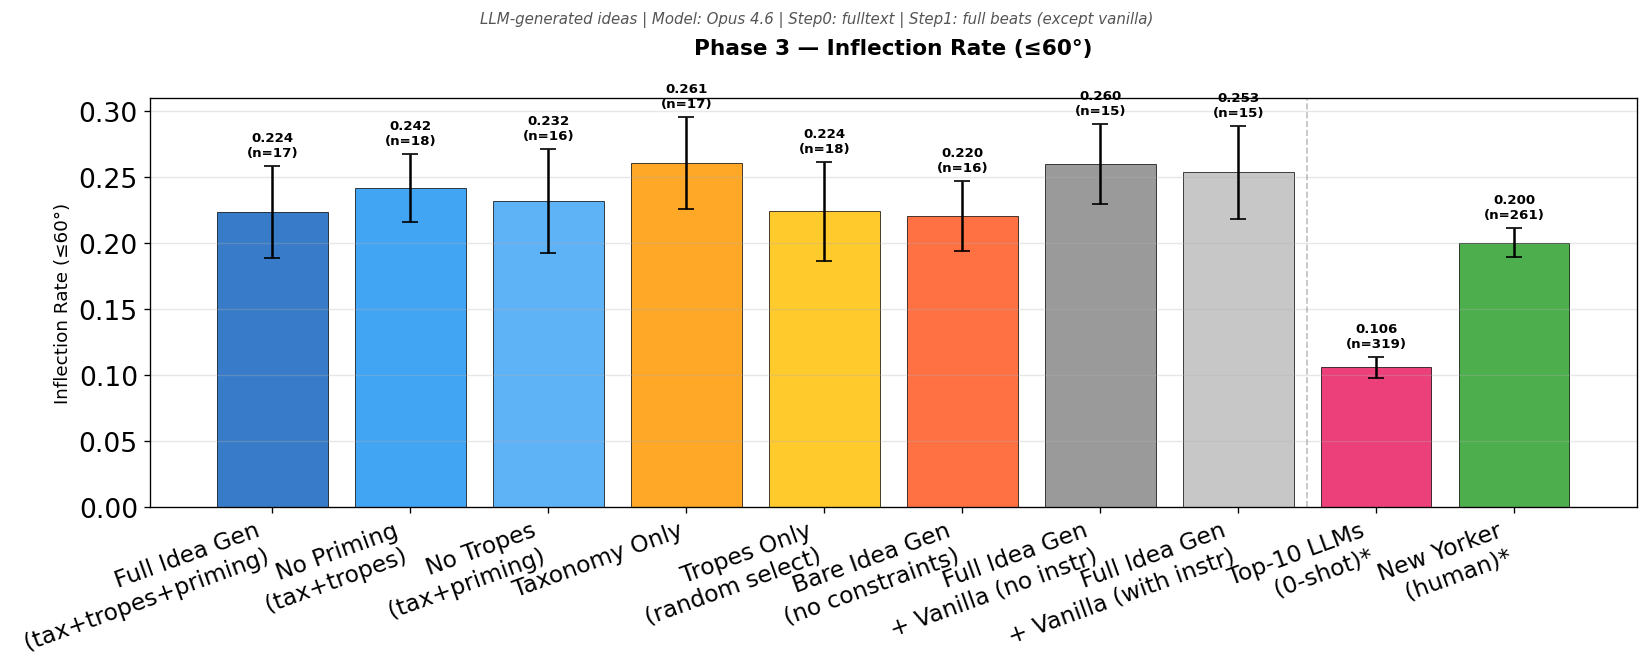

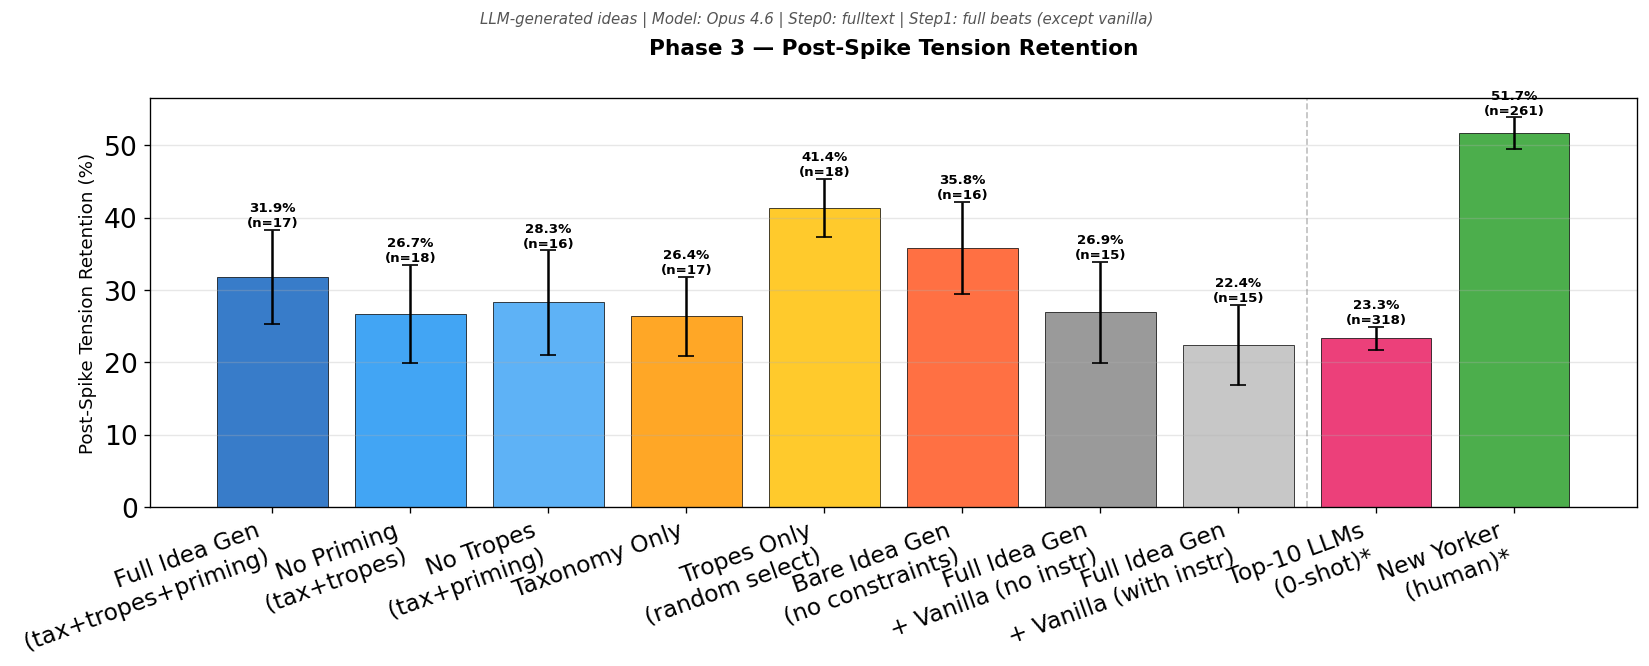

In [7]:
PH3_CONFIGS = [
    'idea_full', 'idea_no_priming', 'idea_no_tropes',
    'idea_tax_only', 'idea_tropes_only', 'idea_bare',
    'idea_vanilla', 'idea_instruction_vanilla',
]
PH3_LABELS = [
    'Full Idea Gen\n(tax+tropes+priming)',
    'No Priming\n(tax+tropes)',
    'No Tropes\n(tax+priming)',
    'Taxonomy Only',
    'Tropes Only\n(random select)',
    'Bare Idea Gen\n(no constraints)',
    'Full Idea Gen\n+ Vanilla (no instr)',
    'Full Idea Gen\n+ Vanilla (with instr)',
]
PH3_COLORS = [
    '#1565C0', '#2196F3', '#42A5F5',
    '#FF9800', '#FFC107', '#FF5722',
    '#888888',
    '#BDBDBD', '#E91E63',
]
PH3_SUB = 'LLM-generated ideas | Model: Opus 4.6 | Step0: fulltext | Step1: full beats (except vanilla)'

for metric, ylabel, title_suffix in [
    ('mean_nr', 'Average No-Rate', 'Mean No-Rate'),
    ('late_nr', f'Late-Stage No-Rate (≥{LATE_PCT}%)', f'Late-Stage No-Rate (≥{LATE_PCT}%)'),
    ('inflection_60', 'Inflection Rate (≤60°)', 'Inflection Rate (≤60°)'),
    ('post_spike_retention', 'Post-Spike Tension Retention (%)', 'Post-Spike Tension Retention'),
]:
    plot_metric_bars(
        PH3_CONFIGS, PH3_LABELS, PH3_COLORS, metric,
        f'Phase 3 — {title_suffix}', ylabel, subtitle=PH3_SUB,
    )

In [8]:
# ── Phase 3: Complete Results Table ──────────────────────────────────────────

print('=' * 110)
print('Phase 3 — All Metrics')
print('=' * 110)
print(f"{'Config':<30s} {'Tax':>3} {'Trp':>3} {'Prm':>3} {'Step1':>6} {'n':>4}"
      f"  {'Mean NR':>12}  {'Late NR':>12}  {'Inflect60':>12}  {'Retain%':>12}")
print('-' * 110)

ph3_meta = {
    'idea_full':                 ('\u2713', '\u2713', '\u2713', 'beats'),
    'idea_no_priming':           ('\u2713', '\u2713', '\u2717', 'beats'),
    'idea_no_tropes':            ('\u2713', '\u2717', '\u2713', 'beats'),
    'idea_tax_only':             ('\u2713', '\u2717', '\u2717', 'beats'),
    'idea_tropes_only':          ('\u2717', '\u2713', '\u2717', 'beats'),
    'idea_bare':                 ('\u2717', '\u2717', '\u2717', 'beats'),
    'idea_vanilla':              ('\u2713', '\u2713', '\u2713', 'none'),
    'idea_instruction_vanilla':  ('\u2713', '\u2713', '\u2713', 'instr'),
}

# Sort by mean_nr descending
rows = []
for cfg in PH3_CONFIGS:
    m = get_config_metrics(cfg)
    if m is None:
        rows.append((cfg, 0, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan))
        continue
    mnr_m, mnr_ci = np.mean(m['mean_nr']), 1.96*np.std(m['mean_nr'])/np.sqrt(len(m['mean_nr']))
    lnr_m = np.mean(m['late_nr']) if len(m['late_nr']) > 0 else np.nan
    lnr_ci = 1.96*np.std(m['late_nr'])/np.sqrt(len(m['late_nr'])) if len(m['late_nr']) > 0 else 0
    ir_m = np.mean(m['inflection_60']) if len(m['inflection_60']) > 0 else np.nan
    ir_ci = 1.96*np.std(m['inflection_60'])/np.sqrt(len(m['inflection_60'])) if len(m['inflection_60']) > 0 else 0
    ret_m = np.mean(m['post_spike_retention']) if len(m['post_spike_retention']) > 0 else np.nan
    ret_ci = 1.96*np.std(m['post_spike_retention'])/np.sqrt(len(m['post_spike_retention'])) if len(m['post_spike_retention']) > 0 else 0
    rows.append((cfg, len(m['mean_nr']), mnr_m, mnr_ci, lnr_m, lnr_ci, ir_m, ir_ci, ret_m, ret_ci))

rows.sort(key=lambda x: -x[2] if not np.isnan(x[2]) else 0)

for cfg, n, mnr_m, mnr_ci, lnr_m, lnr_ci, ir_m, ir_ci, ret_m, ret_ci in rows:
    tax, trp, prm, s1 = ph3_meta.get(cfg, ('?','?','?','?'))
    if np.isnan(mnr_m):
        print(f'{cfg:<30s} {tax:>3} {trp:>3} {prm:>3} {s1:>6} {"—":>4}  {"— no data —":>52}')
        continue
    print(f'{cfg:<30s} {tax:>3} {trp:>3} {prm:>3} {s1:>6} {n:>4}'
          f'  {mnr_m:>.3f}\u00b1{mnr_ci:.3f}'
          f'  {lnr_m:>.3f}\u00b1{lnr_ci:.3f}'
          f'  {ir_m:>.3f}\u00b1{ir_ci:.3f}'
          f'  {ret_m:>5.1f}%\u00b1{ret_ci:.1f}')

# Reference baselines
print('-' * 110)
ref = REFS
print(f"{'Top-10 LLMs (0-shot)*':<30s} {'':>3} {'':>3} {'':>3} {'':>6} {ref['mean_nr']['llm_n']:>4}"
      f"  {ref['mean_nr']['llm_mean']:>.3f}\u00b1{ref['mean_nr']['llm_ci']:.3f}"
      f"  {ref['late_nr']['llm_mean']:>.3f}\u00b1{ref['late_nr']['llm_ci']:.3f}"
      f"  {ref['inflection_60']['llm_mean']:>.3f}\u00b1{ref['inflection_60']['llm_ci']:.3f}"
      f"  {ref['post_spike_retention']['llm_mean']:>5.1f}%\u00b1{ref['post_spike_retention']['llm_ci']:.1f}")
print(f"{'New Yorker (human)*':<30s} {'':>3} {'':>3} {'':>3} {'':>6} {ref['mean_nr']['nyer_n']:>4}"
      f"  {ref['mean_nr']['nyer_mean']:>.3f}\u00b1{ref['mean_nr']['nyer_ci']:.3f}"
      f"  {ref['late_nr']['nyer_mean']:>.3f}\u00b1{ref['late_nr']['nyer_ci']:.3f}"
      f"  {ref['inflection_60']['nyer_mean']:>.3f}\u00b1{ref['inflection_60']['nyer_ci']:.3f}"
      f"  {ref['post_spike_retention']['nyer_mean']:>5.1f}%\u00b1{ref['post_spike_retention']['nyer_ci']:.1f}")
print('=' * 110)


Phase 3 — All Metrics
Config                         Tax Trp Prm  Step1    n       Mean NR       Late NR     Inflect60       Retain%
--------------------------------------------------------------------------------------------------------------
idea_tropes_only                 ✗   ✓   ✗  beats   18  0.690±0.041  0.407±0.067  0.224±0.037   41.4%±4.0
idea_bare                        ✗   ✗   ✗  beats   16  0.645±0.080  0.391±0.088  0.220±0.026   35.8%±6.4
idea_no_tropes                   ✓   ✗   ✓  beats   16  0.578±0.088  0.324±0.094  0.232±0.040   28.3%±7.2
idea_vanilla                     ✓   ✓   ✓   none   15  0.572±0.073  0.387±0.109  0.260±0.031   26.9%±7.0
idea_full                        ✓   ✓   ✓  beats   17  0.566±0.078  0.364±0.071  0.224±0.035   31.9%±6.5
idea_tax_only                    ✓   ✗   ✗  beats   17  0.515±0.079  0.301±0.070  0.261±0.035   26.4%±5.5
idea_no_priming                  ✓   ✓   ✗  beats   18  0.509±0.088  0.289±0.086  0.242±0.026   26.7%±6.8
idea_instructi

## EQ-Bench Evaluation — Rubric Leaderboard + No-Rate Comparison

Our narrative pipeline (Sonnet 4.6 + precomputed warmup + beats) was also evaluated on the **EQ-Bench Creative Writing v3** benchmark using the standard 32 story prompts. Two complementary views:

**Left:** EQ-Bench rubric score leaderboard (top 10). Our pipeline achieves **84.58/100**, placing it #1 on the rubric leaderboard — above GPT-5.4 (84.45).

**Right:** No-rate comparison on the **same 32 EQ-Bench prompts** — a direct apples-to-apples comparison. Unlike Phases 1–3 (which use our custom 15 story ideas), this comparison uses identical prompts for both vanilla and pipeline stories.

*Note: EQ-Bench stories are shorter (~1000 words per prompt specification) than our custom stories (~2500 words). No word count filter is applied here — all stories are included.*

cwb_vanilla_sonnet46: 0.5773 ±0.0620 (n=32, 3 reps)
cwb_narrative_sonnet46: 0.7023 ±0.0427 (n=32, 3 reps)


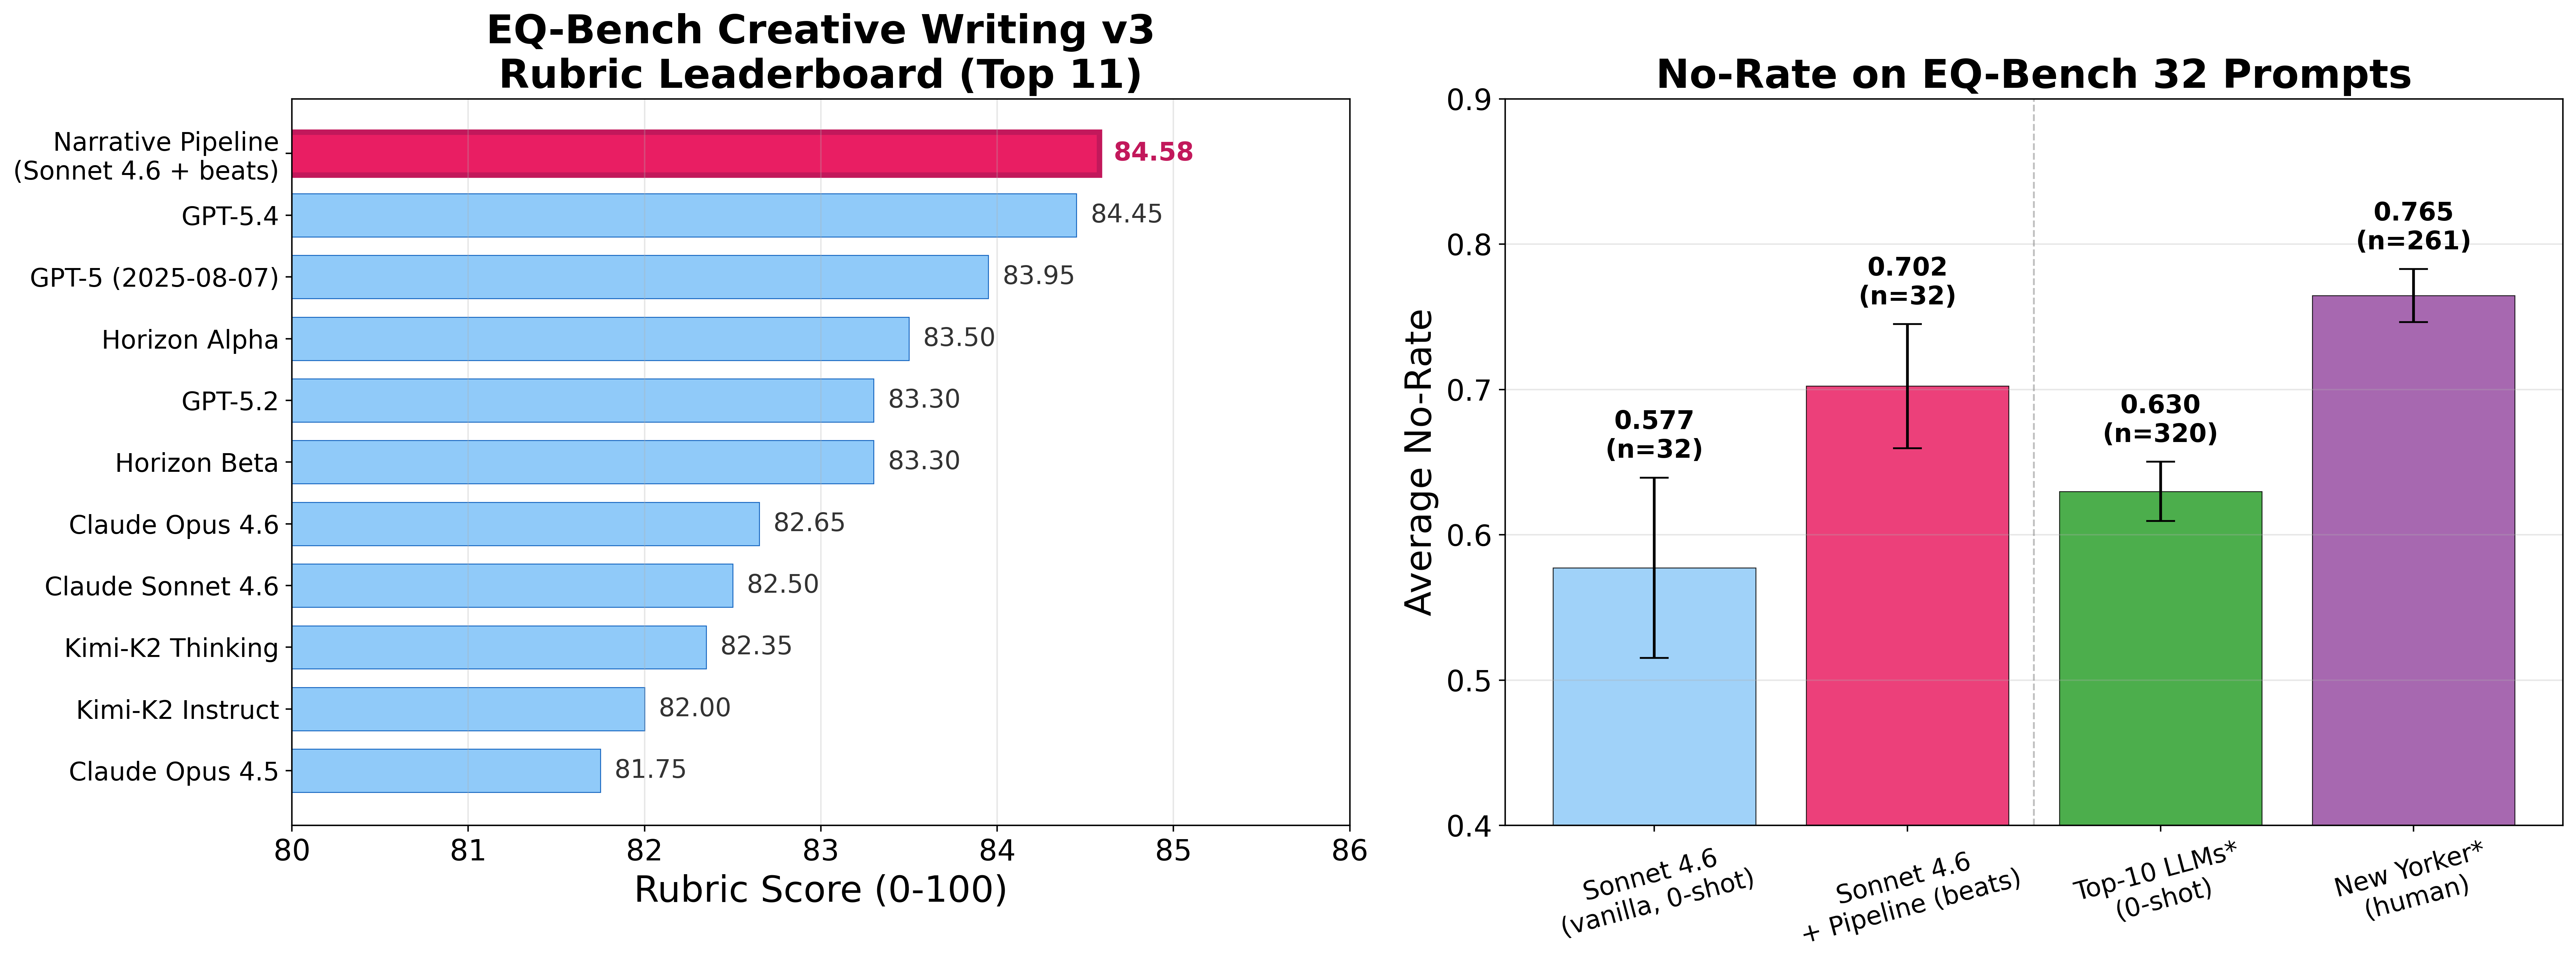


EQ-Bench Prompts: All 4 Metrics (iter1, averaged across 3 reps)
Source                                                n Reps   Mean NR   Late NR   Inflect   Retain%
-----------------------------------------------------------------------------------------------
Sonnet 4.6 (vanilla)                                 32    3     0.577     0.133     0.087     15.8%
Sonnet 4.6 + Pipeline                                32    3     0.702     0.317     0.146     33.0%
-----------------------------------------------------------------------------------------------
Top-10 LLMs (0-shot)*                               320    —     0.630     0.215     0.106     23.3%
New Yorker*                                         261    —     0.765     0.607     0.200     51.7%
-----------------------------------------------------------------------------------------------
  DELTA (pipeline - vanilla)                                    +0.125    +0.184    +0.059    +17.2%

Per-rep breakdown (iter1 only):
  Vanill

In [29]:
# ── Side-by-side: EQ-Bench Rubric Leaderboard + No-Rate on same prompts ────────
# No-Rate: averaged across reps 1-3 (iter1 only, 32 stories per rep)

import os as _os

# Paper-quality font sizes
PAPER_RC = {
    'font.size': 18,
    'axes.titlesize': 22,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16,
}

with plt.rc_context(PAPER_RC):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    # ═══════════════════════════════════════════════════════════════════════════
    # LEFT: EQ-Bench Rubric Score Leaderboard (top 10 + ours)
    # ═══════════════════════════════════════════════════════════════════════════

    leaderboard = [
        ('Narrative Pipeline\n(Sonnet 4.6 + beats)', 84.58, True),
        ('GPT-5.4',                                   84.45, False),
        ('GPT-5 (2025-08-07)',                        83.95, False),
        ('Horizon Alpha',                              83.50, False),
        ('GPT-5.2',                                    83.30, False),
        ('Horizon Beta',                               83.30, False),
        ('Claude Opus 4.6',                            82.65, False),
        ('Claude Sonnet 4.6',                          82.50, False),
        ('Kimi-K2 Thinking',                           82.35, False),
        ('Kimi-K2 Instruct',                           82.00, False),
        ('Claude Opus 4.5',                            81.75, False),
    ]

    names = [x[0] for x in leaderboard]
    scores = [x[1] for x in leaderboard]
    is_ours = [x[2] for x in leaderboard]

    y = np.arange(len(names))[::-1]
    colors_lb = ['#E91E63' if o else '#90CAF9' for o in is_ours]
    edge_lb = ['#C2185B' if o else '#1565C0' for o in is_ours]
    lw_lb = [3.0 if o else 0.5 for o in is_ours]

    bars1 = ax1.barh(y, scores, color=colors_lb, edgecolor=edge_lb, linewidth=lw_lb, height=0.7)
    ax1.set_yticks(y)
    ax1.set_yticklabels(names, fontsize=14)
    ax1.set_xlabel('Rubric Score (0-100)', fontsize=20)
    ax1.set_xlim(80, 86)
    ax1.set_title('EQ-Bench Creative Writing v3\nRubric Leaderboard (Top 11)', fontsize=22, fontweight='bold')
    ax1.grid(axis='x', alpha=0.3)

    for bar, s, o in zip(bars1, scores, is_ours):
        ax1.text(bar.get_width() + 0.08, bar.get_y() + bar.get_height()/2,
                 f'{s:.2f}', va='center', fontsize=14,
                 fontweight='bold' if o else 'normal',
                 color='#C2185B' if o else '#333333')

    # ═══════════════════════════════════════════════════════════════════════════
    # RIGHT: No-Rate comparison — averaged across reps 1-3 (iter1 only)
    # ═══════════════════════════════════════════════════════════════════════════

    ABL_BASE = '/project/jevans/maxzhuyt/narrative_project/narrative_ablation/results'
    USE_REPS = [1, 2, 3]

    def load_multi_rep_norate(cfg):
        rep_story_nrs = {}
        n_reps_found = 0
        for rep in USE_REPS:
            jpath = f"{ABL_BASE}/judge/{cfg}_judge.json" if rep == 1 else f"{ABL_BASE}/judge_rep{rep}/{cfg}_judge.json"
            if not _os.path.exists(jpath): continue
            d = json.load(open(jpath))
            n_reps_found += 1
            for sid, v in d.items():
                if "_iter1" not in sid: continue
                pos = v.get('positions', [])
                if not pos: continue
                nrs = [1 - p['yes_rate'] for p in pos]
                rep_story_nrs.setdefault(sid, []).append(float(np.mean(nrs)))
        story_means = [np.mean(nrs) for nrs in rep_story_nrs.values()]
        return np.array(story_means), n_reps_found

    cwb_configs = [
        ('cwb_vanilla_sonnet46',    'Sonnet 4.6\n(vanilla, 0-shot)', '#90CAF9'),
        ('cwb_narrative_sonnet46',  'Sonnet 4.6\n+ Pipeline (beats)', '#E91E63'),
    ]

    bar_labels_r, bar_means_r, bar_cis_r, bar_colors_r, bar_counts_r = [], [], [], [], []
    bar_missing_r = []

    for i, (cfg, label, color) in enumerate(cwb_configs):
        story_means, n_reps = load_multi_rep_norate(cfg)
        if len(story_means) == 0:
            bar_labels_r.append(label); bar_means_r.append(0); bar_cis_r.append(0)
            bar_colors_r.append(color); bar_counts_r.append(0); bar_missing_r.append(i)
            continue
        bar_labels_r.append(label)
        bar_means_r.append(float(np.mean(story_means)))
        bar_cis_r.append(1.96 * np.std(story_means) / np.sqrt(len(story_means)))
        bar_colors_r.append(color)
        bar_counts_r.append(len(story_means))
        print(f'{cfg}: {np.mean(story_means):.4f} ±{bar_cis_r[-1]:.4f} (n={len(story_means)}, {n_reps} reps)')

    # Reference baselines
    bar_labels_r.extend(['Top-10 LLMs*\n(0-shot)', 'New Yorker*\n(human)'])
    ref_mnr = REFS['mean_nr']
    bar_means_r.extend([ref_mnr['llm_mean'], ref_mnr['nyer_mean']])
    bar_cis_r.extend([ref_mnr['llm_ci'], ref_mnr['nyer_ci']])
    bar_colors_r.extend(['#2ca02c', '#984ea3'])
    bar_counts_r.extend([ref_mnr['llm_n'], ref_mnr['nyer_n']])

    x2 = np.arange(len(bar_means_r))
    bars2 = ax2.bar(x2, bar_means_r, yerr=bar_cis_r, capsize=8,
                    color=bar_colors_r, edgecolor='black', linewidth=0.5, alpha=0.85)

    for i in bar_missing_r:
        bars2[i].set_alpha(0.2); bars2[i].set_hatch('//')

    ax2.axvline(len(cwb_configs) - 0.5, color='gray', linewidth=1, linestyle='--', alpha=0.5)
    ax2.set_xticks(x2)
    ax2.set_xticklabels(bar_labels_r, rotation=15, ha='center', fontsize=14)
    ax2.set_ylabel('Average No-Rate', fontsize=20)
    ax2.set_ylim(0.40, 0.90)
    ax2.set_title('No-Rate on EQ-Bench 32 Prompts', fontsize=22, fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)

    for i, (bar, m, ci, n) in enumerate(zip(bars2, bar_means_r, bar_cis_r, bar_counts_r)):
        if i in bar_missing_r: continue
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + ci + 0.01,
                 f'{m:.3f}\n(n={n})', ha='center', va='bottom', fontsize=14, fontweight='bold')


    plt.tight_layout(rect=[0, 0.04, 1, 1])
    FIG_DIR = '/project/jevans/maxzhuyt/narrative_project/figures'
    _os.makedirs(FIG_DIR, exist_ok=True)
    plt.savefig(f'{FIG_DIR}/eqbench_leaderboard_norate.png', dpi=400, bbox_inches='tight')
    plt.show()

# ── Multi-metric table: averaged across reps 1-3 ─────────────────────────────

def load_multi_rep_all_metrics(cfg):
    rep_data = {}
    n_reps = 0
    for rep in USE_REPS:
        jpath = f"{ABL_BASE}/judge/{cfg}_judge.json" if rep == 1 else f"{ABL_BASE}/judge_rep{rep}/{cfg}_judge.json"
        if not _os.path.exists(jpath): continue
        d = json.load(open(jpath))
        n_reps += 1
        for sid, v in d.items():
            if "_iter1" not in sid: continue
            pos = v.get('positions', [])
            if not pos: continue
            m = {
                'mean_nr': story_no_rate_mean(pos),
                'late_nr': story_no_rate_late(pos),
                'inflection_60': story_inflection_rate(pos, 60),
                'post_spike_retention': story_post_spike_retention(pos),
            }
            rep_data.setdefault(sid, []).append(m)
    results = {'mean_nr': [], 'late_nr': [], 'inflection_60': [], 'post_spike_retention': []}
    for sid, rep_metrics in rep_data.items():
        for key in results:
            vals = [m[key] for m in rep_metrics if not np.isnan(m[key])]
            if vals:
                results[key].append(np.mean(vals))
    for k in results:
        results[k] = np.array(results[k])
    return results, n_reps

print()
print('=' * 95)
print('EQ-Bench Prompts: All 4 Metrics (iter1, averaged across 3 reps)')
print('=' * 95)
print(f"{'Source':<50s} {'n':>4} {'Reps':>4} {'Mean NR':>9} {'Late NR':>9} {'Inflect':>9} {'Retain%':>9}")
print('-' * 95)

for cfg, label in [('cwb_vanilla_sonnet46', 'Sonnet 4.6 (vanilla)'),
                     ('cwb_narrative_sonnet46', 'Sonnet 4.6 + Pipeline')]:
    m, n_reps = load_multi_rep_all_metrics(cfg)
    if not len(m['mean_nr']):
        print(f'{label:<50s}  — no data')
        continue
    print(f'{label:<50s} {len(m["mean_nr"]):>4} {n_reps:>4} '
          f'{np.mean(m["mean_nr"]):>9.3f} {np.mean(m["late_nr"]):>9.3f} '
          f'{np.mean(m["inflection_60"]):>9.3f} {np.mean(m["post_spike_retention"]):>8.1f}%')

print('-' * 95)
for metric_label, refs_key in [('Top-10 LLMs (0-shot)*', 'llm'), ('New Yorker*', 'nyer')]:
    n = REFS['mean_nr'][f'{refs_key}_n']
    print(f'{metric_label:<50s} {n:>4} {"—":>4} '
          f'{REFS["mean_nr"][f"{refs_key}_mean"]:>9.3f} '
          f'{REFS["late_nr"][f"{refs_key}_mean"]:>9.3f} '
          f'{REFS["inflection_60"][f"{refs_key}_mean"]:>9.3f} '
          f'{REFS["post_spike_retention"][f"{refs_key}_mean"]:>8.1f}%')

# Delta
m_van, _ = load_multi_rep_all_metrics('cwb_vanilla_sonnet46')
m_nar, _ = load_multi_rep_all_metrics('cwb_narrative_sonnet46')
if len(m_van['mean_nr']) and len(m_nar['mean_nr']):
    print('-' * 95)
    print(f"{'  DELTA (pipeline - vanilla)':<50s} {'':>4} {'':>4} "
          f'{np.mean(m_nar["mean_nr"])-np.mean(m_van["mean_nr"]):>+9.3f} '
          f'{np.mean(m_nar["late_nr"])-np.mean(m_van["late_nr"]):>+9.3f} '
          f'{np.mean(m_nar["inflection_60"])-np.mean(m_van["inflection_60"]):>+9.3f} '
          f'{np.mean(m_nar["post_spike_retention"])-np.mean(m_van["post_spike_retention"]):>+8.1f}%')

# Per-rep breakdown
print()
print('Per-rep breakdown (iter1 only):')
for cfg, label in [('cwb_vanilla_sonnet46', 'Vanilla'), ('cwb_narrative_sonnet46', 'Narrative')]:
    print(f'  {label}:')
    for rep in USE_REPS:
        jpath = f"{ABL_BASE}/judge/{cfg}_judge.json" if rep == 1 else f"{ABL_BASE}/judge_rep{rep}/{cfg}_judge.json"
        if not _os.path.exists(jpath): continue
        d = json.load(open(jpath))
        nrs = []
        for sid, v in d.items():
            if "_iter1" not in sid: continue
            pos = v.get('positions', [])
            if pos:
                nrs.append(np.mean([1-p['yes_rate'] for p in pos]))
        if nrs:
            print(f'    Rep {rep}: mean_nr={np.mean(nrs):.4f} (n={len(nrs)})')
# save fig 
fig.savefig(f'{FIG_DIR}/eqbench_leaderboard_norate.png', dpi=500, bbox_inches='tight')